# Ontario Waste Generation and Recycling Patterns
**MIA 5126 · Applied Data Science Project**  
**Analysis period:** 2011–2021 · **Geography:** Ontario reporting programs

We investigate how residential waste generation and diversion evolved, how performance differs across reporting programs, and whether prior-year information can help anticipate diversion rates. We also identify groups of programs with similar profiles and compare each program with its closest reporting peers. Our conclusions describe associations, not causal effects.

## 1. Data sources and analytical workflow
We use our team's consolidated SQLite database, built from annual RPRA workbooks, and review its source lineage and quality flags before analysis. Its program-year keys make it possible to combine reported residential waste, Blue Box and organics measures without duplicating program records. We keep 2021 census geographies separate: program service areas do not necessarily correspond to municipalities. Our analysis follows source → validation → integration → exploration → modelling → evaluation.

In [1]:
from pathlib import Path
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, silhouette_score

pd.set_option('display.max_columns', 22)
plt.rcParams.update({'figure.figsize':(9,4.5), 'axes.grid':True, 'grid.alpha':.2})
DB_PATH = Path('ontario_waste (1).sqlite')
if not DB_PATH.exists():
    DB_PATH = Path('/mnt/data/ontario_waste (1).sqlite')
assert DB_PATH.exists(), 'Place ontario_waste (1).sqlite next to this notebook.'
with sqlite3.connect(DB_PATH) as con:
    waste = pd.read_sql_query('SELECT * FROM waste_indicators', con)
    organics = pd.read_sql_query('SELECT program_code, year, total_organics_collected_tonnes FROM organics', con)
    bluebox = pd.read_sql_query('SELECT program_code, year, total_marketed_tonnes FROM blue_box_tonnage', con)
    issues = pd.read_sql_query('SELECT * FROM quality_issues', con)
    census = pd.read_sql_query('SELECT * FROM census_demographics', con)
    coverage = pd.read_sql_query('SELECT * FROM dataset_coverage', con)
    sources = pd.read_sql_query('SELECT year, dataset_type, relative_path FROM source_files', con)
    integrity = con.execute('PRAGMA integrity_check').fetchone()[0]
assert integrity == 'ok'
print(f'Waste program-years: {len(waste):,}; programs: {waste.program_code.nunique()}; years: {waste.year.min()}–{waste.year.max()}')
print(f'Other data: organics {len(organics):,} rows, Blue Box {len(bluebox):,} rows, census {len(census):,} geographies')
print('SQLite integrity:', integrity)
display(sources.groupby('dataset_type').agg(files=('relative_path','count'), earliest=('year','min'), latest=('year','max')))

Waste program-years: 1,787; programs: 258; years: 2011–2021
Other data: organics 1,784 rows, Blue Box 2,651 rows, census 577 geographies
SQLite integrity: ok


,files,earliest,latest
dataset_type,,,
accepted_materials,11,2011.0,2021.0
blue_box_financials,11,2011.0,2021.0
blue_box_tonnage,11,2011.0,2021.0
census_demographics,1,NaN,NaN
organics,11,2011.0,2021.0
other_recyclables,11,2011.0,2021.0
residential_waste,11,2011.0,2021.0


## 2. Data quality and integration
We test record uniqueness, completeness, valid ranges and the mass balance between generated, diverted and disposed tonnes. We preserve reported anomalies and exclude invalid observations only where a calculation requires valid values. We join detail tables using **both** program code and year; we do not treat missing information as zero.

In [2]:
assert not waste.duplicated(['program_code','year']).any()
assert not organics.duplicated(['program_code','year']).any()
assert not bluebox.duplicated(['program_code','year']).any()
assert waste.year.between(2011,2021).all()
fields = ['waste_generated_tonnes','waste_diverted_tonnes','waste_disposed_tonnes',
          'population_with_seasonal','diversion_rate_pct']
profile = pd.DataFrame({'missing_count':waste[fields].isna().sum(),
                        'missing_%':(100*waste[fields].isna().mean()).round(2)})
display(profile)
waste['balance_gap_tonnes'] = waste.waste_generated_tonnes - waste.waste_diverted_tonnes - waste.waste_disposed_tonnes
print('Quality flags in source:',len(issues))
display(issues[['year','program_code','issue']])
valid = waste.loc[(waste.waste_generated_tonnes > 0) &
                  (waste.waste_diverted_tonnes >= 0) &
                  (waste.waste_disposed_tonnes >= 0) &
                  (waste.population_with_seasonal > 0) &
                  waste.diversion_rate_pct.between(0,100)].copy()
print(f'Rows retained with valid primary indicators: {len(valid):,}/{len(waste):,}')
panel = valid.merge(organics, on=['program_code','year'], how='left', validate='one_to_one')
panel = panel.merge(bluebox, on=['program_code','year'], how='left', validate='one_to_one')
assert len(panel)==len(valid)
display(panel.groupby('year').agg(programs=('program_code','nunique'),
             with_organics=('total_organics_collected_tonnes','count'),
             with_bluebox=('total_marketed_tonnes','count')))

,missing_count,missing_%
waste_generated_tonnes,0,0.0
waste_diverted_tonnes,0,0.0
waste_disposed_tonnes,0,0.0
population_with_seasonal,0,0.0
diversion_rate_pct,0,0.0


Quality flags in source: 1


,year,program_code,issue
0,2012,36,mass_balance_mismatch


Rows retained with valid primary indicators: 1,787/1,787


,programs,with_organics,with_bluebox
year,,,
2011,231,231,231
2012,230,230,230
2013,226,226,226
2014,237,237,237
2015,243,243,243
2016,105,105,105
2017,112,109,112
2018,102,102,102
2019,106,106,106


## 3. Reporting coverage and province-wide trends
We aggregate generated and diverted tonnage only across the programs that reported in each year. The **tonnage-weighted diversion rate** is the sum of diverted tonnes divided by the sum of generated tonnes, rather than an average of program percentages. Changes in coverage mean these totals should not be interpreted as an exact census of Ontario.

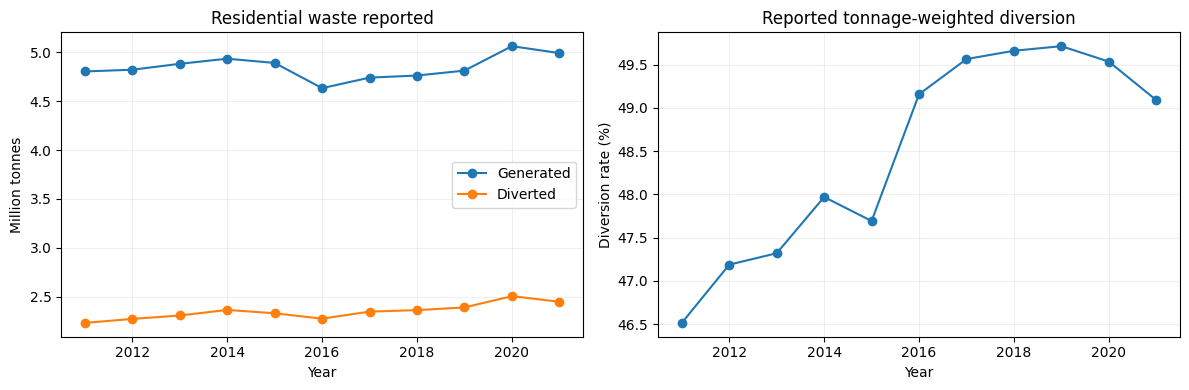

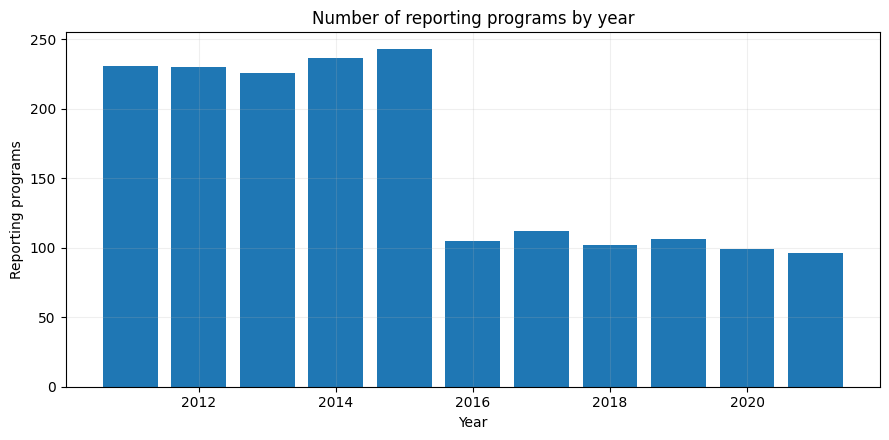

,year,programs,generated_tonnes,diverted_tonnes,disposed_tonnes,weighted_diversion_pct
0,2011,231,4803075.94,2234161.59,2568914.35,46.52
1,2012,230,4820654.61,2274810.24,2545869.37,47.19
2,2013,226,4881134.06,2309779.63,2571354.43,47.32
3,2014,237,4933307.81,2366544.45,2566763.36,47.97
4,2015,243,4890025.00,2332220.41,2557804.59,47.69
5,2016,105,4632565.32,2277308.98,2355256.34,49.16
6,2017,112,4739901.57,2349374.07,2390527.51,49.57
7,2018,102,4761408.28,2364602.87,2396805.41,49.66
8,2019,106,4811585.79,2392076.55,2419509.24,49.71
9,2020,99,5061340.05,2507202.67,2554137.38,49.54


In [3]:
annual = (valid.groupby('year',as_index=False)
          .agg(programs=('program_code','nunique'), generated_tonnes=('waste_generated_tonnes','sum'),
               diverted_tonnes=('waste_diverted_tonnes','sum'), disposed_tonnes=('waste_disposed_tonnes','sum')))
annual['weighted_diversion_pct'] = 100*annual.diverted_tonnes/annual.generated_tonnes
fig,axes = plt.subplots(1,2,figsize=(12,4))
axes[0].plot(annual.year,annual.generated_tonnes/1e6,marker='o',label='Generated')
axes[0].plot(annual.year,annual.diverted_tonnes/1e6,marker='o',label='Diverted')
axes[0].set(ylabel='Million tonnes',xlabel='Year',title='Residential waste reported');axes[0].legend()
axes[1].plot(annual.year,annual.weighted_diversion_pct,marker='o')
axes[1].set(xlabel='Year',ylabel='Diversion rate (%)',title='Reported tonnage-weighted diversion')
plt.tight_layout();plt.show()
fig,ax=plt.subplots()
ax.bar(annual.year,annual.programs)
ax.set(xlabel='Year',ylabel='Reporting programs',title='Number of reporting programs by year')
plt.tight_layout();plt.show()
display(annual.round(2))

## 4. Program differences and recycling streams
We review variation among programs and inspect the separately reported organics and Blue Box streams. These streams may differ from diversion components in the main residential-waste table, so we **do not add them to diverted tonnes**. Their purpose here is descriptive comparison, not double-counting.

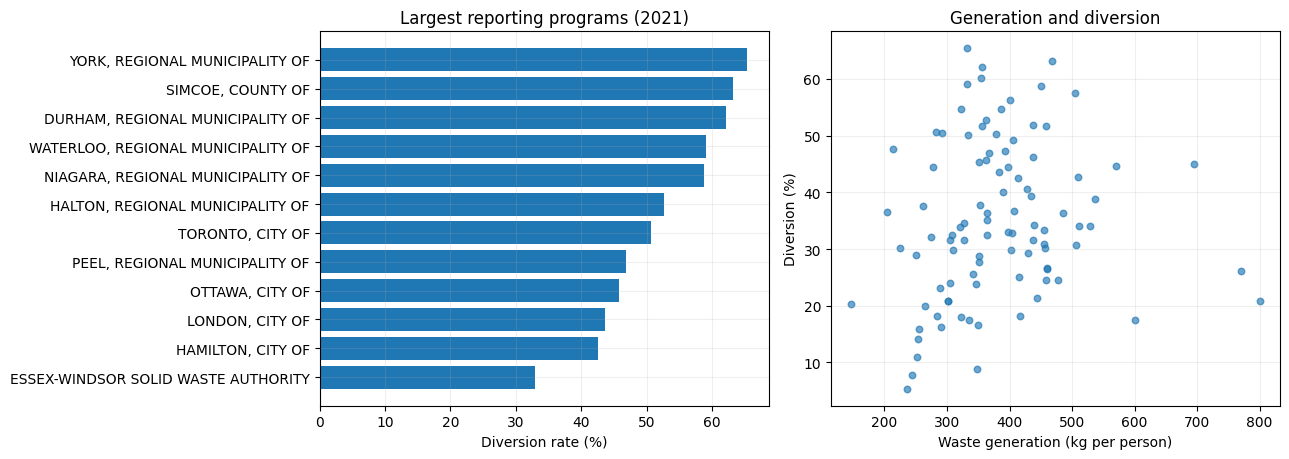

,count,mean,std,min,25%,50%,75%,max,available_rows
total_organics_collected_tonnes,96.0,12774.8,36166.1,0.0,0.0,319.5,5818.6,255514.5,96
total_marketed_tonnes,96.0,7360.9,15948.4,6.8,305.7,893.6,5388.7,94359.4,96
waste_generated_tonnes,96.0,51985.6,119894.7,139.8,1884.0,5323.1,38321.0,791309.6,96


Caution: Blue Box marketed tonnes and collected organics are not necessarily directly additive or equivalent to total diverted tonnes.


In [4]:
latest_year=int(panel.year.max())
latest=panel.query('year == @latest_year').copy()
large=latest.nlargest(12,'waste_generated_tonnes').sort_values('diversion_rate_pct')
fig,axes=plt.subplots(1,2,figsize=(13,4.7))
axes[0].barh(large.program_name,large.diversion_rate_pct)
axes[0].set(xlabel='Diversion rate (%)',title=f'Largest reporting programs ({latest_year})')
axes[1].scatter(latest.generated_kg_per_capita,latest.diversion_rate_pct,alpha=.65,s=22)
axes[1].set(xlabel='Waste generation (kg per person)',ylabel='Diversion (%)',title='Generation and diversion')
plt.tight_layout();plt.show()
stream=latest[['total_organics_collected_tonnes','total_marketed_tonnes','waste_generated_tonnes']].describe().T
stream['available_rows']=latest[['total_organics_collected_tonnes','total_marketed_tonnes','waste_generated_tonnes']].notna().sum()
display(stream.round(1))
print('Caution: Blue Box marketed tonnes and collected organics are not necessarily directly additive or equivalent to total diverted tonnes.')

## 5. Time patterns and comparability checks
Our observations are annual, so we can examine trends and year-to-year persistence, but not monthly seasonality. We compare all reporting programs with programs present in every year. We also look at the relationship between a program's diversion rate and its preceding year's rate.

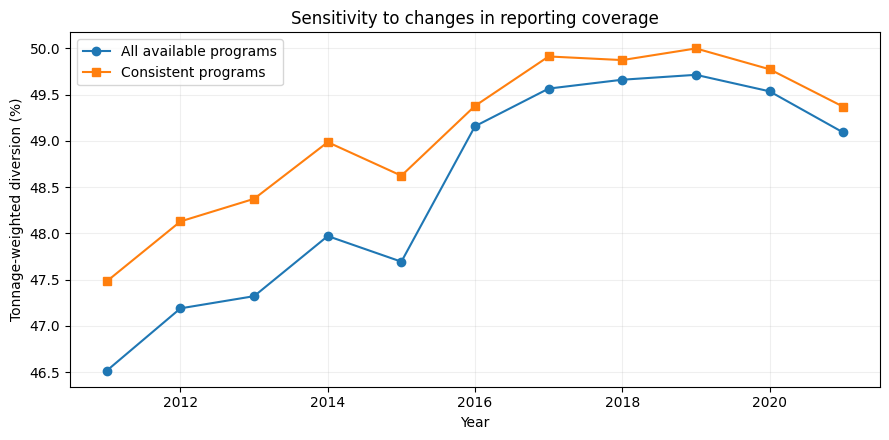

Consistent programs: 67 | Consecutive-year pairs: 1469
One-year diversion-rate correlation: 0.871


In [5]:
n_years=valid.year.nunique()
consistent_ids=valid.groupby('program_code').year.nunique().loc[lambda s:s==n_years].index
balanced=valid[valid.program_code.isin(consistent_ids)]
balanced_annual=(balanced.groupby('year',as_index=False)
    .agg(generated=('waste_generated_tonnes','sum'),diverted=('waste_diverted_tonnes','sum')))
balanced_annual['rate']=100*balanced_annual.diverted/balanced_annual.generated
fig,ax=plt.subplots()
ax.plot(annual.year,annual.weighted_diversion_pct,marker='o',label='All available programs')
ax.plot(balanced_annual.year,balanced_annual.rate,marker='s',label='Consistent programs')
ax.set(xlabel='Year',ylabel='Tonnage-weighted diversion (%)',title='Sensitivity to changes in reporting coverage');ax.legend()
plt.tight_layout();plt.show()
lag_view=valid.sort_values(['program_code','year']).copy()
lag_view['prev_year']=lag_view.groupby('program_code').year.shift(1)
lag_view['prev_rate']=lag_view.groupby('program_code').diversion_rate_pct.shift(1)
consecutive=lag_view[lag_view.year-lag_view.prev_year==1].dropna(subset=['prev_rate'])
print('Consistent programs:',len(consistent_ids),'| Consecutive-year pairs:',len(consecutive))
print('One-year diversion-rate correlation:',round(consecutive[['prev_rate','diversion_rate_pct']].corr().iloc[0,1],3))

## 6. Discovering similar reporting-program profiles
We explore whether programs form distinct groups using **Gaussian mixture clustering**. We use interpretable 2021 characteristics, standardize the variables, and select the number of groups by the Bayesian Information Criterion (BIC). We show a two-dimensional PCA view for communication; PCA coordinates are not evidence of geographical proximity or causal similarity. Clusters are exploratory and may change with the selected features.

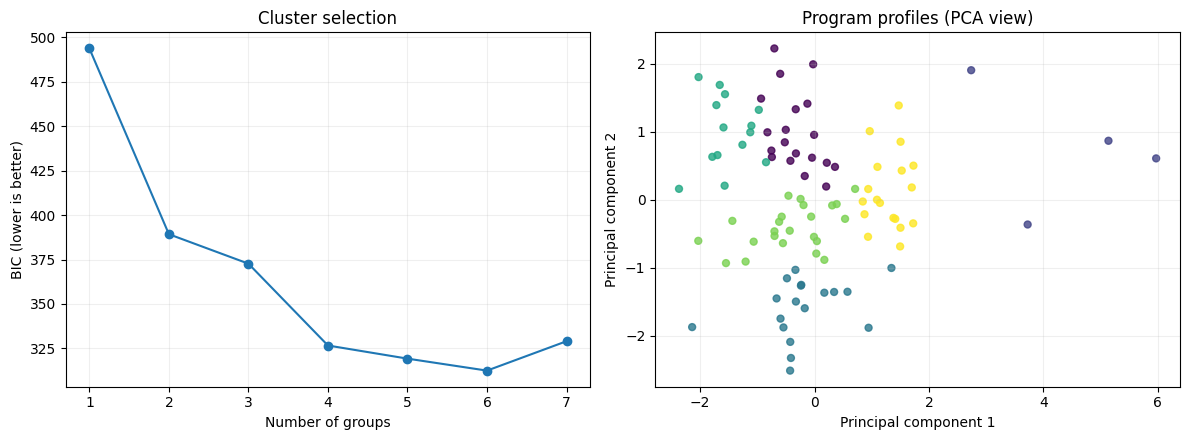

,programs,diversion_pct,generation_kg,disposal_kg
cluster,,,,
0,19,48.0,416.6,215.3
1,4,27.3,716.3,520.1
2,18,16.5,288.7,240.7
3,14,53.5,325.1,149.9
4,23,32.0,330.1,224.5
5,18,31.4,477.7,325.7


Selected number of clusters: 6
Exploratory silhouette score: 0.329


In [6]:
cluster_features=['diversion_rate_pct','generated_kg_per_capita','disposed_kg_per_capita']
cluster_frame=latest[['program_code','program_name']+cluster_features].replace([np.inf,-np.inf],np.nan).dropna().copy()
assert len(cluster_frame)>=20
scaler=StandardScaler();Z=scaler.fit_transform(cluster_frame[cluster_features])
candidates=range(1,min(7,len(cluster_frame)//10)+1)
fitted={k:GaussianMixture(n_components=k,random_state=42,reg_covar=1e-4,n_init=5).fit(Z) for k in candidates}
bics={k:model.bic(Z) for k,model in fitted.items()}
best_k=min(bics,key=bics.get)
cluster_frame['cluster']=fitted[best_k].predict(Z)
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
axes[0].plot(list(bics),list(bics.values()),marker='o')
axes[0].set(xlabel='Number of groups',ylabel='BIC (lower is better)',title='Cluster selection')
projection=PCA(n_components=2).fit_transform(Z)
axes[1].scatter(projection[:,0],projection[:,1],c=cluster_frame.cluster,cmap='viridis',s=25,alpha=.8)
axes[1].set(xlabel='Principal component 1',ylabel='Principal component 2',title='Program profiles (PCA view)')
plt.tight_layout();plt.show()
summary=cluster_frame.groupby('cluster').agg(programs=('program_code','size'),
    diversion_pct=('diversion_rate_pct','mean'),generation_kg=('generated_kg_per_capita','mean'),
    disposal_kg=('disposed_kg_per_capita','mean'))
display(summary.round(1))
print('Selected number of clusters:',best_k)
if best_k>1 and cluster_frame.cluster.value_counts().min()>1:
    print('Exploratory silhouette score:',round(silhouette_score(Z,cluster_frame.cluster),3))

## 7. Peer comparison based on similarity
To make the clusters more actionable, we identify nearby peers in the **standardized feature space**. This is a similarity-based benchmarking tool—not a recommendation of specific municipal policies, because the dataset does not establish which interventions caused the outcomes. We do not use collaborative filtering or association rules: the data contains no user preferences or item transactions.

In [7]:
# Compare a large reporting program with its nearest profiles; exclude itself.
reference=cluster_frame.merge(latest[['program_code','waste_generated_tonnes']],on='program_code',validate='one_to_one')
chosen_code=int(reference.nlargest(1,'waste_generated_tonnes').program_code.iloc[0])
pos=int(np.flatnonzero(cluster_frame.program_code.to_numpy()==chosen_code)[0])
distances=np.linalg.norm(Z-Z[pos],axis=1)
peer_idx=np.argsort(distances)[1:6]
print('Reference reporting program:',cluster_frame.iloc[pos].program_name)
display(cluster_frame.iloc[peer_idx][['program_name']+cluster_features+['cluster']].round(1))

Reference reporting program: TORONTO, CITY OF


,program_name,diversion_rate_pct,generated_kg_per_capita,disposed_kg_per_capita,cluster
1713,QUINTE WASTE SOLUTIONS,50.5,291.6,144.4,3
1723,"DUFFERIN, COUNTY OF",54.7,322.8,146.1,3
1785,"WOLLASTON, TOWNSHIP OF",44.5,277.7,154.2,3
1711,"WELLINGTON, COUNTY OF",50.2,334.1,166.5,3
1726,"OWEN SOUND, CITY OF",47.7,213.2,111.5,3


## 8. Forecasting next-year diversion rates
Our prediction task is to estimate a program's diversion rate in year **t** using data observed in year **t − 1**. We require consecutive observations, use only lagged predictors, and split by calendar year to avoid training on future data. We compare a last-year-value baseline with Ridge Regression and Random Forest. We select the method on 2019 validation records, then evaluate it on unseen 2020–2021 records.

In [8]:
model_panel=valid.sort_values(['program_code','year']).copy()
lag_columns=['diversion_rate_pct','generated_kg_per_capita','disposed_kg_per_capita',
             'population_with_seasonal','waste_generated_tonnes']
for col in lag_columns:
    model_panel['lag1_'+col]=model_panel.groupby('program_code')[col].shift(1)
model_panel['previous_year']=model_panel.groupby('program_code').year.shift(1)
model_panel=model_panel[model_panel.year-model_panel.previous_year==1].copy()
features=['lag1_'+col for col in lag_columns]
model_data=model_panel.dropna(subset=['diversion_rate_pct','lag1_diversion_rate_pct']).copy()
train=model_data[model_data.year<=2018]
validation=model_data[model_data.year==2019]
test=model_data[model_data.year>=2020]
for tag,frame in [('Training',train),('Validation',validation),('Test',test)]:
    print(f'{tag}: {len(frame)} observations, years {sorted(frame.year.unique())}')
assert min(len(train),len(validation),len(test))>0

def scores(y,pred):
    return {'MAE (percentage points)':mean_absolute_error(y,pred),
            'RMSE (percentage points)':np.sqrt(mean_squared_error(y,pred)),
            'R²':r2_score(y,pred)}
def make_model(name):
    if name=='Ridge':
        return Pipeline([('fill',SimpleImputer(strategy='median')),
            ('scale',StandardScaler()),('model',Ridge(alpha=10))])
    return Pipeline([('fill',SimpleImputer(strategy='median')),
            ('model',RandomForestRegressor(n_estimators=160,min_samples_leaf=5,
                                          max_features=.8,random_state=42,n_jobs=1))])
predictions={'Carry-forward baseline':validation.lag1_diversion_rate_pct.to_numpy()}
for name in ['Ridge','Random Forest']:
    m=make_model(name);m.fit(train[features],train.diversion_rate_pct)
    predictions[name]=np.clip(m.predict(validation[features]),0,100)
validation_scores=pd.DataFrame({name:scores(validation.diversion_rate_pct,p)
                                for name,p in predictions.items()}).T.sort_values('MAE (percentage points)')
display(validation_scores.round(3))
selected=validation_scores.index[0]
print('Method selected on 2019 validation data:',selected)

Training: 1204 observations, years [np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018)]
Validation: 88 observations, years [np.int64(2019)]
Test: 177 observations, years [np.int64(2020), np.int64(2021)]


,MAE (percentage points),RMSE (percentage points),R²
Carry-forward baseline,3.047,5.068,0.847
Random Forest,3.284,5.278,0.834
Ridge,3.345,4.865,0.859


Method selected on 2019 validation data: Carry-forward baseline


## 9. Independent test results and limitations
We retrain the selected method on years through 2019 and assess predictive accuracy on 2020–2021. MAE is reported in **percentage points**, making errors easy to interpret. R² can be negative when performance is worse than a constant-mean predictor. Our test is a historical one-year-ahead assessment, not a claim of causal impact or a reliable forecast for current conditions.

,MAE (percentage points),RMSE (percentage points),R²
Carry-forward baseline,3.465,5.52,0.819
Selected: Carry-forward baseline,3.465,5.52,0.819


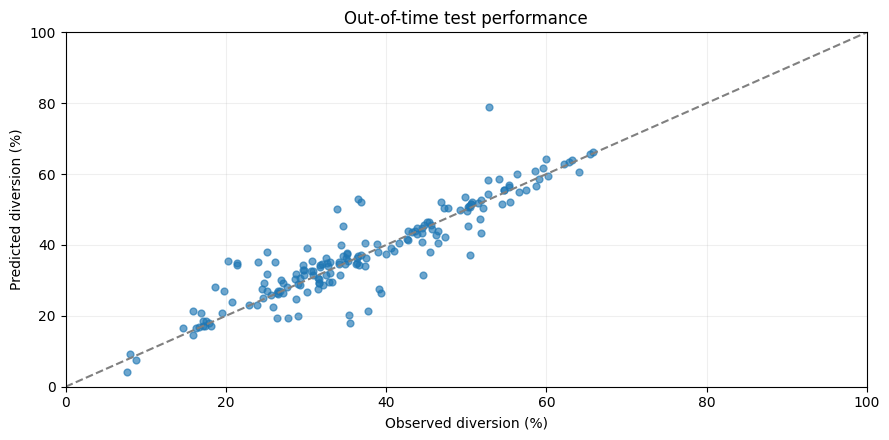

,observations,MAE_pp
year,,
2020,93,3.875
2021,84,3.011


In [9]:
train_final=model_data[model_data.year<=2019]
if selected=='Carry-forward baseline':
    test_predictions=test.lag1_diversion_rate_pct.to_numpy()
else:
    final_model=make_model(selected)
    final_model.fit(train_final[features],train_final.diversion_rate_pct)
    test_predictions=np.clip(final_model.predict(test[features]),0,100)
baseline_predictions=test.lag1_diversion_rate_pct.to_numpy()
test_scores=pd.DataFrame({
    'Carry-forward baseline':scores(test.diversion_rate_pct,baseline_predictions),
    'Selected: '+selected:scores(test.diversion_rate_pct,test_predictions)}).T
display(test_scores.round(3))
fig,ax=plt.subplots()
ax.scatter(test.diversion_rate_pct,test_predictions,s=24,alpha=.65)
ax.plot([0,100],[0,100],ls='--',color='gray')
ax.set(xlim=(0,100),ylim=(0,100),xlabel='Observed diversion (%)',
       ylabel='Predicted diversion (%)',title='Out-of-time test performance')
plt.tight_layout();plt.show()
by_year=test.assign(abs_error=np.abs(test.diversion_rate_pct.to_numpy()-test_predictions)).groupby('year').agg(
    observations=('program_code','size'),MAE_pp=('abs_error','mean'))
display(by_year.round(3))

## 10. Demographic data: appropriate scope
We inspect the census information as secondary geographic context. We do not merge it into the forecasting panel: census subdivision boundaries and RPRA program service areas can differ, and the available population data describes 2016 and 2021 rather than every reporting year. A verified service-area crosswalk would be required before combining them for municipality-level inference.

In [10]:
print('Census rows:',len(census),'| Unique geographic IDs:',census.dguid.nunique())
assert census.dguid.is_unique
census_profile=census[['population_2016','population_2021','population_density_2021']].describe()
display(census_profile.round(1))
print('No census-to-RPRA geographic join was attempted.')

Census rows: 577 | Unique geographic IDs: 577


,population_2016,population_2021,population_density_2021
count,569.0,564.0,564.0
mean,23635.9,25219.8,166.8
std,133325.4,138532.7,417.3
min,0.0,0.0,0.0
25%,503.0,530.0,5.2
50%,2662.0,2826.5,16.6
75%,10263.0,10909.5,76.6
max,2731571.0,2794356.0,4427.8


No census-to-RPRA geographic join was attempted.


## 11. What we learned
We interpret the figures alongside changing reporting coverage, missing values and variations in program size. Our **descriptive trends** show what participating programs reported; our **clustering** identifies similarities, not proven explanations; and our **forecasting** demonstrates how well preceding-year outcomes predict later diversion rates. We would next validate municipality-to-program boundaries, investigate important quality flags, and test forecasting with additional years before recommending specific policy changes.

In [11]:
print(f'Across {annual.year.min()}–{annual.year.max()}, weighted diversion changed from '
      f'{annual.weighted_diversion_pct.iloc[0]:.1f}% to {annual.weighted_diversion_pct.iloc[-1]:.1f}%.')
print(f'The complete-coverage sensitivity set contains {len(consistent_ids)} programs.')
print(f'The selected test MAE was {scores(test.diversion_rate_pct,test_predictions)["MAE (percentage points)"]:.2f} percentage points.')
print(f'The exploratory cluster analysis identified {best_k} program profile groups.')

Across 2011–2021, weighted diversion changed from 46.5% to 49.1%.
The complete-coverage sensitivity set contains 67 programs.
The selected test MAE was 3.46 percentage points.
The exploratory cluster analysis identified 6 program profile groups.


## Source documentation and reproducibility
- Resource Productivity and Recovery Authority (RPRA), Ontario municipal waste workbooks, 2011–2021, consolidated by our project team.
- Statistics Canada, 2016/2021 census municipal population and dwelling summary, provided in the team's database.
- Team database builder and database notes supplied with the project files.

**To reproduce:** Place `ontario_waste (1).sqlite` beside this notebook, install `numpy`, `pandas`, `matplotlib`, `scikit-learn`, and run all cells in order. The original imported data and quality flags remain unchanged. The report still needs a literature review and formal references before submission.